# 02 — Weather drivers and baseline forecasts

Goal: understand how temperature drives Ontario demand, then set the bar any real model has to beat.

Data: IESO hourly Ontario demand 2019–2026 + hourly Toronto weather (Open-Meteo archive), built by `src/data.py`.

In [1]:
import sys; sys.path.append("..") if "notebooks" in __import__("os").getcwd() else None
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import build_dataset
from src.features import clean, add_calendar, add_weather

df = add_weather(add_calendar(clean(build_dataset())))
df.tail()

,demand_mw,market_demand_mw,temp_c,rh_pct,cloud_pct,hour,dow,month,doy,is_weekend,is_holiday,doy_sin,doy_cos,hdd,cdd,temp_day_mean,temp_prev_day_mean
datetime,,,,,,,,,,,,,,,,,
2026-10-01 20:00:00,17487.0,19061.0,21.1,78.0,100.0,20,3,10,274,0,0,-0.999999,0.001075,0.0,3.1,19.9375,17.7500
2026-10-01 21:00:00,16598.0,18331.0,20.6,82.0,100.0,21,3,10,274,0,0,-0.999999,0.001075,0.0,2.6,19.9375,17.7500
2026-10-01 22:00:00,15788.0,18149.0,19.7,90.0,100.0,22,3,10,274,0,0,-0.999999,0.001075,0.0,1.7,19.9375,17.7500
2026-10-01 23:00:00,15141.0,17584.0,19.9,90.0,100.0,23,3,10,274,0,0,-0.999999,0.001075,0.0,1.9,19.9375,17.7500
2026-10-02 00:00:00,14883.0,17574.0,19.3,89.0,100.0,0,4,10,275,0,0,-0.999833,0.018277,0.0,1.3,19.3000,19.9375


## Demand vs temperature
Ontario demand is U-shaped in temperature: heating load below the minimum (~12–14 °C daily mean) and air-conditioning load above ~18 °C, rising steeply past 25 °C. A straight-line correlation (r ≈ 0.02) hides this completely.

Pearson r (demand, temp): 0.022


Temperature of minimum demand (bin midpoint): 14.0 °C


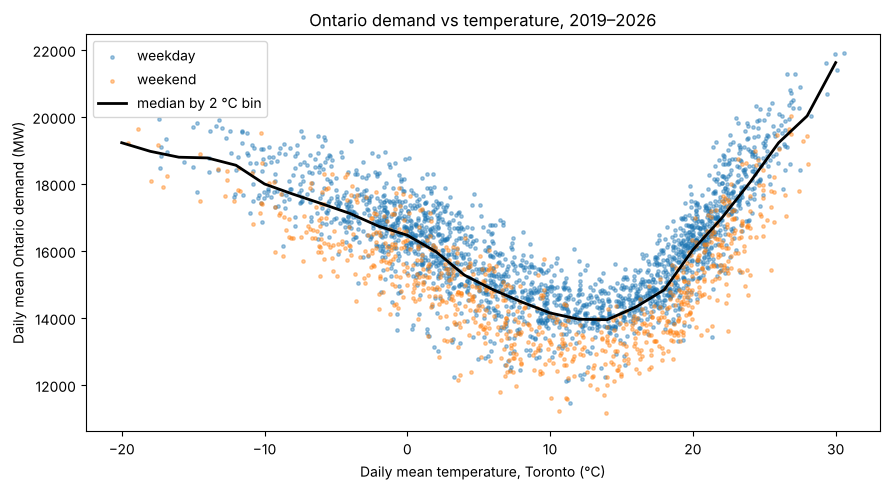

In [2]:
print("Pearson r (demand, temp):", round(df["demand_mw"].corr(df["temp_c"]), 3))

daily = df.resample("D").agg(demand_mw=("demand_mw", "mean"), temp_c=("temp_c", "mean"), is_weekend=("is_weekend", "max"))
fig, ax = plt.subplots(figsize=(9, 5))
for wk, g in daily.groupby("is_weekend"):
    ax.scatter(g["temp_c"], g["demand_mw"], s=6, alpha=0.4, label="weekend" if wk else "weekday")
bins = pd.cut(daily["temp_c"], np.arange(-25, 36, 2))
curve = daily.groupby(bins, observed=True)["demand_mw"].median()
ax.plot([b.mid for b in curve.index], curve.values, color="black", lw=2, label="median by 2 °C bin")
ax.set(xlabel="Daily mean temperature, Toronto (°C)", ylabel="Daily mean Ontario demand (MW)",
       title="Ontario demand vs temperature, 2019–2026")
ax.legend()
fig.tight_layout(); fig.savefig("figures/demand_vs_temperature.png", dpi=130)
print("Temperature of minimum demand (bin midpoint):", curve.idxmin().mid, "°C")

## Daily shape by season
Winter has a morning and a strong ~18:00 evening peak (lighting + heating); summer has a single broad afternoon peak driven by cooling.

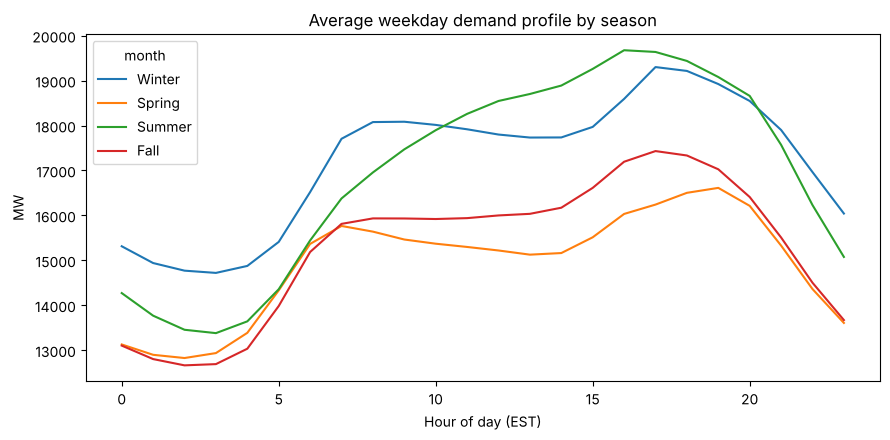

In [3]:
season = df["month"].map({12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
                         6:"Summer",7:"Summer",8:"Summer",9:"Fall",10:"Fall",11:"Fall"})
prof = df[df["is_weekend"] == 0].groupby([season, "hour"])["demand_mw"].mean().unstack(0)
ax = prof[["Winter", "Spring", "Summer", "Fall"]].plot(figsize=(9, 4.5), title="Average weekday demand profile by season")
ax.set(xlabel="Hour of day (EST)", ylabel="MW")
plt.tight_layout(); plt.savefig("figures/seasonal_daily_profile.png", dpi=130)

## Annual trend
Yearly averages show whether underlying load is growing (electrification, data centres, population) — important context for any model trained on past years.

In [4]:
annual = df.loc[:"2025", "demand_mw"].resample("YE").agg(["mean", "max"])
annual.index = annual.index.year
annual.round(0)

,mean,max
datetime,,
2019,15423.0,21791.0
2020,15053.0,24446.0
2021,15279.0,22986.0
2022,15704.0,22607.0
2023,15654.0,23713.0
2024,15986.0,23852.0
2025,16621.0,24862.0


## Baselines

Setup used throughout the project: **day-ahead** — at the end of day D-1, forecast every hour of day D.
Test period: **calendar year 2025** (never used for fitting).

- **Persistence (lag 24 h):** tomorrow's hour h = today's hour h.
- **Weekly persistence (lag 168 h):** = same hour one week ago.
- **Average of both.**

In [5]:
def metrics(y, yhat):
    err = yhat - y
    return pd.Series({"MAE (MW)": err.abs().mean(),
                      "RMSE (MW)": np.sqrt((err**2).mean()),
                      "MAPE (%)": (err.abs() / y).mean() * 100})

y = df["demand_mw"]
test = df.loc["2025"].index
baselines = {
    "Persistence (lag 24h)": y.shift(24),
    "Weekly persistence (lag 168h)": y.shift(168),
    "Average of lag 24h & 168h": (y.shift(24) + y.shift(168)) / 2,
}
res = pd.DataFrame({k: metrics(y[test], v[test]) for k, v in baselines.items()}).T.round(1)
res.to_csv("results/baselines_2025.csv")
res

,MAE (MW),RMSE (MW),MAPE (%)
Persistence (lag 24h),758.0,1030.4,4.6
Weekly persistence (lag 168h),1197.0,1673.0,7.0
Average of lag 24h & 168h,808.5,1105.6,4.8


These numbers are the bar for notebook 03: a useful model must clearly beat ~the best baseline above, especially on peak hours.